# Post-hoc analysis: Food labels (`grummon2025`) arm ordering & relative magnitude

Tests whether off-the-shelf and choice-trained KEV models recover the **ordering and relative magnitude** of the 6 front-of-package warning-label arms on the **Food labels** held-out test dataset (Grummon et al. 2025; $N = 5{,}633$ respondents, $33{,}798$ tasks, `Positive` reference $= 0$).

In [1]:
from pathlib import Path
import sys

from IPython.display import display
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm
import statsmodels.api as sm

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

CODE_DIR = next(
    (
        c
        for p in (Path.cwd(), *Path.cwd().parents)
        for c in (p, p / "code")
        if all((c / d).is_dir() for d in ("kev", "data", "models"))
    ),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"Could not locate code/ root above {Path.cwd()}")

PAPER_DIR = CODE_DIR / "papers" / "sim-respondents"
SRC_DIR = PAPER_DIR / "src"
if not (SRC_DIR / "microdata_analysis.py").is_file():
    raise FileNotFoundError(f"Expected microdata_analysis.py in {SRC_DIR}")

for path_str in (str(CODE_DIR), str(CODE_DIR / "kev")):
    if path_str not in sys.path:
        sys.path.insert(0, path_str)
src_str = str(SRC_DIR)
while src_str in sys.path:
    sys.path.remove(src_str)
sys.path.insert(0, src_str)

import microdata_analysis as ma
from beta_ols import grummon2025

# 1. Load Food labels dataset and fit respondent-clustered human OLS
choice_df = grummon2025.load_choice_df()
reg_rows = grummon2025.regression_rows(choice_df)
specs = grummon2025.regression_specs(reg_rows)
spec = specs[grummon2025.NAME]

group_rows = reg_rows[reg_rows["group"] == grummon2025.NAME].reset_index(drop=True)
if len(group_rows) != len(choice_df):
    raise ValueError(f"Expected {len(choice_df)} regression rows, got {len(group_rows)}")

X_human = group_rows[spec.design_columns].astype(float)
y_human = group_rows["y"].astype(float)
human_fit = sm.OLS(y_human, X_human).fit(
    cov_type="cluster",
    cov_kwds={"groups": group_rows["CASEID"]},
)

expected_terms = list(spec.target_labels)
human_betas = human_fit.params[expected_terms].astype(float)
human_se = human_fit.bse[expected_terms].astype(float)
V_human = human_fit.cov_params().loc[expected_terms, expected_terms].to_numpy(dtype=float)
V_human_inv = np.linalg.inv(V_human)

# Order all 6 arms top-to-bottom from highest to lowest in the human benchmark
arm_order_desc = [*list(human_betas.sort_values(ascending=False).index), "Positive"]
human_vals_desc = np.array([0.0 if a == "Positive" else float(human_betas[a]) for a in arm_order_desc])
human_se_desc = np.array([0.0 if a == "Positive" else float(human_se[a]) for a in arm_order_desc])

# Human statistically distinct tiers (within-tier p > 0.35; all cross-tier p < 1.4e-5)
V6 = np.zeros((6, 6), dtype=float)
for i, ai in enumerate(arm_order_desc):
    if ai == "Positive":
        continue
    ii = expected_terms.index(ai)
    for j, aj in enumerate(arm_order_desc):
        if aj == "Positive":
            continue
        jj = expected_terms.index(aj)
        V6[i, j] = V_human[ii, jj]

sig_human_pairs: list[tuple[int, int, float]] = []
for i in range(6):
    for j in range(i + 1, 6):
        diff = human_vals_desc[i] - human_vals_desc[j]
        se_ij = float(np.sqrt(V6[i, i] + V6[j, j] - 2.0 * V6[i, j]))
        p_ij = float(2.0 * (1.0 - norm.cdf(abs(diff / se_ij))))
        if p_ij < 0.05:
            sig_human_pairs.append((i, j, float(np.sign(diff))))

# Expected rank range per arm based on the 4 human tiers
TIER_RANK_RANGE = {
    "NutritionInfo vs Positive": (1, 2),
    "Positive+NutritionInfo vs Positive": (1, 2),
    "Positive+HighIn vs Positive": (3, 4),
    "Spectrum vs Positive": (3, 4),
    "HighIn vs Positive": (5, 5),
    "Positive": (6, 6),
}
ARM_DISPLAY = {
    "NutritionInfo vs Positive": "NutritionInfo",
    "Positive+NutritionInfo vs Positive": "Pos + NutritionInfo",
    "Positive+HighIn vs Positive": "Pos + HighIn",
    "Spectrum vs Positive": "Spectrum",
    "HighIn vs Positive": "HighIn",
    "Positive": "Positive (ref)",
}

# 2. Load verified KEV test_best OLS slopes: Off-the-shelf vs. full training dataset (Drones + Electricity)
RUN_ROOTS = (PAPER_DIR / "runs-rorqual", PAPER_DIR / "runs-nibi")
MODELS = ("kev-0.8b", "kev-4b", "kev-9b")
MODEL_LABELS = {"kev-0.8b": "KEV-0.8B", "kev-4b": "KEV-4B", "kev-9b": "KEV-9B"}
BASE_SLUG = "row1_base_untrained"
TRAINED_SLUGS = ("row5_full_berke_wu_ce_oracle",)
ALL_SLUGS = (BASE_SLUG, *TRAINED_SLUGS)
REGIME_LABELS = {
    BASE_SLUG: "Off-the-shelf",
    "row5_full_berke_wu_ce_oracle": "Drones + Electricity",
}

ctx = ma.load_microdata_context(
    run_roots=RUN_ROOTS,
    models=MODELS,
    base_slug=BASE_SLUG,
    trained_slugs=TRAINED_SLUGS,
    validators=("kriner2026", "grummon2025"),
)

bh = human_betas.to_numpy(dtype=float)
kev_vals_desc: dict[tuple[str, str], np.ndarray] = {}
summary_rows: list[dict] = []

for model_slug in MODELS:
    by_slug = ctx.grummon_betas_by_model[model_slug]
    for slug in ALL_SLUGS:
        raw_df = by_slug[slug]
        if list(raw_df.index) != expected_terms:
            raise ValueError(f"Term mismatch for {model_slug}/{slug}: {list(raw_df.index)} != {expected_terms}")
        max_delta = float((raw_df["human_pop_beta"] - human_betas).abs().max())
        if max_delta > 1e-10:
            raise ValueError(f"Human benchmark mismatch for {model_slug}/{slug}: max diff = {max_delta:.3e}")

        bm = raw_df["model_pop_beta"].to_numpy(dtype=float)
        bm_desc = np.array([0.0 if a == "Positive" else float(raw_df.loc[a, "model_pop_beta"]) for a in arm_order_desc])
        kev_vals_desc[(model_slug, slug)] = bm_desc

        a_star = float((bm @ bh) / (bm @ bm))
        if a_star <= 0.0:
            raise ValueError(f"Non-positive optimal scale for {model_slug}/{slug}: a_star={a_star}")

        raw_mse_x1e3 = float(np.mean((bm - bh) ** 2)) * 1000.0
        shape_mse_x1e3 = float(np.mean((a_star * bm - bh) ** 2)) * 1000.0
        cos_sim = float((bm @ bh) / (np.linalg.norm(bm) * np.linalg.norm(bh)))
        ok_pairs = sum(1 for i, j, sgn in sig_human_pairs if np.sign(bm_desc[i] - bm_desc[j]) == sgn)
        a_wald = float((bm @ V_human_inv @ bh) / (bm @ V_human_inv @ bm))
        wald_rel = float((a_wald * bm - bh) @ V_human_inv @ (a_wald * bm - bh))

        # 1-based rank of each arm (1 = highest beta, 6 = lowest beta)
        order_idx = np.argsort(-bm_desc)
        ranks = np.empty(6, dtype=int)
        ranks[order_idx] = np.arange(1, 7)

        summary_rows.append(
            {
                "Model": MODEL_LABELS[model_slug],
                "Regime": REGIME_LABELS[slug],
                "Raw MSE (x1e3)": raw_mse_x1e3,
                "Shape MSE (x1e3)": shape_mse_x1e3,
                "Scale": 1.0 / a_star,
                "Cosine": cos_sim,
                "Sig. pairs": f"{ok_pairs}/{len(sig_human_pairs)}",
                "Rel. Wald (df=4)": wald_rel,
                "_model_slug": model_slug,
                "_slug": slug,
                "_a_star": a_star,
                "_ranks": ranks,
            }
        )

summary_df = pd.DataFrame(summary_rows)
row_lookup = {(r["_model_slug"], r["_slug"]): r for r in summary_rows}
print(
    f"Food labels: N = {group_rows['CASEID'].nunique():,} respondents, {len(group_rows):,} tasks, "
    f"{len(sig_human_pairs)}/15 statistically distinct human pairs (p < 0.05)."
)

Food labels: N = 5,633 respondents, 33,798 tasks, 13/15 statistically distinct human pairs (p < 0.05).


## Summary metrics

In [2]:
display(
    summary_df[
        ["Model", "Regime", "Raw MSE (x1e3)", "Shape MSE (x1e3)", "Scale", "Cosine", "Sig. pairs", "Rel. Wald (df=4)"]
    ]
    .style.format(
        {
            "Raw MSE (x1e3)": "{:.2f}",
            "Shape MSE (x1e3)": "{:.2f}",
            "Scale": "{:.2f}x",
            "Cosine": "{:.3f}",
            "Rel. Wald (df=4)": "{:.1f}",
        }
    )
    .hide(axis="index")
)

Model,Regime,Raw MSE (x1e3),Shape MSE (x1e3),Scale,Cosine,Sig. pairs,Rel. Wald (df=4)
KEV-0.8B,Off-the-shelf,5.46,5.41,0.94x,0.846,10/13,234.6
KEV-0.8B,Drones + Electricity,2.30,2.07,0.88x,0.944,11/13,104.6
KEV-4B,Off-the-shelf,21.10,9.84,2.11x,0.694,11/13,136.1
KEV-4B,Drones + Electricity,2.28,2.24,1.05x,0.939,12/13,67.2
KEV-9B,Off-the-shelf,22.73,5.14,2.13x,0.854,12/13,101.5
KEV-9B,Drones + Electricity,14.82,0.77,1.88x,0.980,12/13,30.2


## Ordering & relative-magnitude comparison (small-multiples staircase)

- Rows are fixed in **human benchmark order** from largest effect (top) to reference `Positive = 0` (bottom), with horizontal dotted rules separating the 4 statistically distinct human tiers.
- **Light gray bar** in every panel = the human benchmark staircase; **foreground bar** = the model's scale-adjusted effect ($a^* \hat{\beta}$) so every panel shares the exact human axis.
- **How to read ordering at a glance:** a model that recovers the human ordering forms a clean descending staircase in **navy** (every arm lands in its human tier). Any arm that violates a significant human tier (rank inversion or wrong sign below `Positive`) is highlighted in **coral red**, with each arm's model rank (`#1`–`#6`) and raw $\hat{\beta}$ printed directly beside the bar.

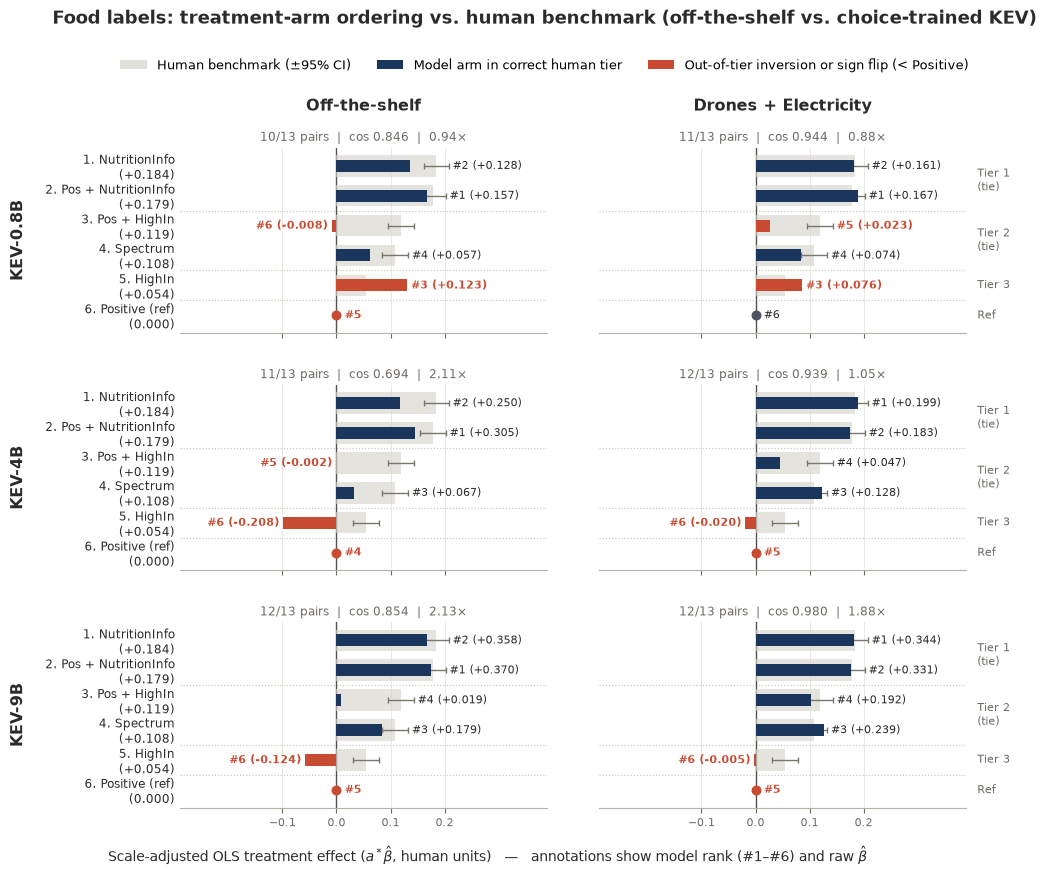

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_food_labels_ordering.png


In [3]:
TEXT_COLOR = "#2B2B2B"
MUTED_COLOR = "#6E6A64"
GRID_COLOR = "#EAE8E2"
HUMAN_GHOST = "#D8D5CD"
OK_COLOR = "#1B365D"      # arm lands in its exact human tier
ERR_COLOR = "#C84B31"     # arm violates a significant human tier (inversion or sign flip)
REF_OK = "#4B5563"        # Positive = 0 when correctly ranked last (#6)

y = np.arange(len(arm_order_desc))
y_labels = [
    f"{i + 1}. {ARM_DISPLAY[a]}\n    ({human_vals_desc[i]:+.3f})"
    if a != "Positive"
    else f"6. {ARM_DISPLAY[a]}\n    (0.000)"
    for i, a in enumerate(arm_order_desc)
]

fig, axes = plt.subplots(
    len(MODELS),
    len(ALL_SLUGS),
    figsize=(11.4, 8.8),
    sharex=True,
    sharey=True,
    gridspec_kw={"hspace": 0.28, "wspace": 0.14},
)

# Tier boundaries (between rows 1-2, 3-4, 4-5 in 0-based top-to-bottom order)
tier_dividers = (1.5, 3.5, 4.5)
tier_side_labels = [
    (0.5, "Tier 1\n(tie)"),
    (2.5, "Tier 2\n(tie)"),
    (4.0, "Tier 3"),
    (5.0, "Ref"),
]

for r_idx, model_slug in enumerate(MODELS):
    for c_idx, slug in enumerate(ALL_SLUGS):
        ax = axes[r_idx, c_idx]
        rec = row_lookup[(model_slug, slug)]
        raw_vals = kev_vals_desc[(model_slug, slug)]
        scaled_vals = rec["_a_star"] * raw_vals
        ranks = rec["_ranks"]

        # Subtle vertical grid + zero reference line + tier dividers
        ax.axvline(0.0, color="#55524D", lw=1.0, zorder=2)
        ax.grid(axis="x", color=GRID_COLOR, lw=0.7, zorder=0)
        for dy in tier_dividers:
            ax.axhline(dy, color="#CBC7BE", lw=0.85, ls=":", zorder=1)

        # Human benchmark ghost staircase behind model bars
        ax.barh(
            y,
            human_vals_desc,
            height=0.72,
            color=HUMAN_GHOST,
            edgecolor="none",
            alpha=0.65,
            zorder=2,
        )
        # Human 95% CI tick marks on ghost bars
        ax.errorbar(
            human_vals_desc[:5],
            y[:5],
            xerr=1.96 * human_se_desc[:5],
            fmt="none",
            ecolor="#7A766E",
            elinewidth=1.0,
            capsize=2.0,
            zorder=3,
        )

        # Model bars, colored by whether each arm lands in its exact human tier
        bar_colors = []
        in_tier_flags = []
        for i, arm in enumerate(arm_order_desc):
            lo, hi = TIER_RANK_RANGE[arm]
            ok = lo <= int(ranks[i]) <= hi
            in_tier_flags.append(ok)
            if arm == "Positive":
                bar_colors.append(REF_OK if ok else ERR_COLOR)
            else:
                bar_colors.append(OK_COLOR if ok else ERR_COLOR)

        ax.barh(
            y,
            scaled_vals,
            height=0.40,
            color=bar_colors,
            edgecolor="none",
            zorder=4,
        )

        # Dot marker for Positive (ref = 0) so its rank badge is visually anchored
        pos_i = 5
        ax.scatter(
            [0.0],
            [y[pos_i]],
            s=38,
            color=bar_colors[pos_i],
            zorder=5,
        )

        # Direct rank badge (#1..#6) + raw beta value next to each bar
        for i, arm in enumerate(arm_order_desc):
            val_s = scaled_vals[i]
            val_r = raw_vals[i]
            rk = int(ranks[i])
            ok = in_tier_flags[i]
            txt_color = TEXT_COLOR if ok else ERR_COLOR
            weight = "normal" if ok else "bold"

            if arm == "Positive":
                label_txt = f" #{rk}"
                ax.text(
                    0.008,
                    y[i],
                    label_txt,
                    va="center",
                    ha="left",
                    fontsize=8.1,
                    color=txt_color,
                    fontweight=weight,
                    zorder=6,
                )
            elif val_s >= 0.0:
                anchor_x = max(val_s, human_vals_desc[i] + 1.96 * human_se_desc[i]) + 0.007
                ax.text(
                    anchor_x,
                    y[i],
                    f"#{rk} ({val_r:+.3f})",
                    va="center",
                    ha="left",
                    fontsize=7.9,
                    color=txt_color,
                    fontweight=weight,
                    zorder=6,
                )
            else:
                ax.text(
                    val_s - 0.007,
                    y[i],
                    f"#{rk} ({val_r:+.3f})",
                    va="center",
                    ha="right",
                    fontsize=7.9,
                    color=txt_color,
                    fontweight=weight,
                    zorder=6,
                )

        # Clean panel header with key ordering/shape summary
        pairs_str = rec["Sig. pairs"]
        perfect_tiers = all(in_tier_flags)
        badge_color = "#1B5E3A" if perfect_tiers else MUTED_COLOR
        sub_txt = f"{pairs_str} pairs  |  cos {rec['Cosine']:.3f}  |  {rec['Scale']:.2f}×"
        ax.set_title(
            sub_txt,
            fontsize=8.6,
            color=badge_color,
            fontweight="bold" if perfect_tiers else "normal",
            pad=5,
        )

        ax.set_xlim(-0.29, 0.39)
        ax.set_ylim(5.6, -0.6)
        ax.set_xticks([-0.1, 0.0, 0.1, 0.2])
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_visible(False)
        ax.spines["bottom"].set_color("#B5B2AA")
        ax.tick_params(axis="y", length=0, colors=TEXT_COLOR, labelsize=8.4)
        ax.tick_params(axis="x", colors=MUTED_COLOR, labelsize=8.2)

        if r_idx == 0:
            ax.text(
                0.5,
                1.18,
                REGIME_LABELS[slug],
                transform=ax.transAxes,
                ha="center",
                va="bottom",
                fontsize=11.5,
                fontweight="bold",
                color=TEXT_COLOR,
            )

        if c_idx == 0:
            ax.set_yticks(y)
            ax.set_yticklabels(y_labels, fontsize=8.3, color=TEXT_COLOR)
            # Row model label on far left
            ax.text(
                -0.44,
                0.5,
                MODEL_LABELS[model_slug],
                transform=ax.transAxes,
                ha="center",
                va="center",
                rotation=90,
                fontsize=11.5,
                fontweight="bold",
                color=TEXT_COLOR,
            )

        if c_idx == len(ALL_SLUGS) - 1:
            for ty, ttxt in tier_side_labels:
                ax.text(
                    1.03,
                    ty,
                    ttxt,
                    transform=ax.get_yaxis_transform(),
                    ha="left",
                    va="center",
                    fontsize=7.6,
                    color=MUTED_COLOR,
                )

fig.supxlabel(
    "Scale-adjusted OLS treatment effect ($a^* \\hat{\\beta}$, human units)   —   annotations show model rank (#1–#6) and raw $\\hat{\\beta}$",
    y=0.02,
    fontsize=9.8,
    color=TEXT_COLOR,
)

legend_handles = [
    mpatches.Patch(facecolor=HUMAN_GHOST, alpha=0.75, label="Human benchmark (±95% CI)"),
    mpatches.Patch(facecolor=OK_COLOR, label="Model arm in correct human tier"),
    mpatches.Patch(facecolor=ERR_COLOR, label="Out-of-tier inversion or sign flip (< Positive)"),
]
fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.55, 0.950),
    ncol=3,
    frameon=False,
    fontsize=9.4,
)
fig.suptitle(
    "Food labels: treatment-arm ordering vs. human benchmark (off-the-shelf vs. choice-trained KEV)",
    y=0.992,
    x=0.55,
    fontsize=13.0,
    fontweight="bold",
    color=TEXT_COLOR,
)
fig.subplots_adjust(top=0.835, bottom=0.085, left=0.23, right=0.92)

out_png = Path("fig_food_labels_ordering.png")
fig.savefig(out_png, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out_png.resolve()}")

# Intuitively show the difference between raw betas and scale adjusted betas
for Kev-9b Drones + Electricity

Arm (Human order),Human beta,Raw KEV-9B,Raw / Human,Scale-adjusted (÷1.88),Raw diff,Scaled diff
NutritionInfo,+0.184,+0.344,1.86x,+0.183,+0.159,-0.001
Pos + NutritionInfo,+0.179,+0.331,1.85x,+0.176,+0.152,-0.003
Pos + HighIn,+0.119,+0.192,1.61x,+0.102,+0.072,-0.017
Spectrum,+0.108,+0.239,2.20x,+0.127,+0.130,+0.019
HighIn,+0.054,-0.005,-0.08x,-0.002,-0.059,-0.057
Positive (ref),+0.000,+0.000,—,+0.000,+0.000,+0.000


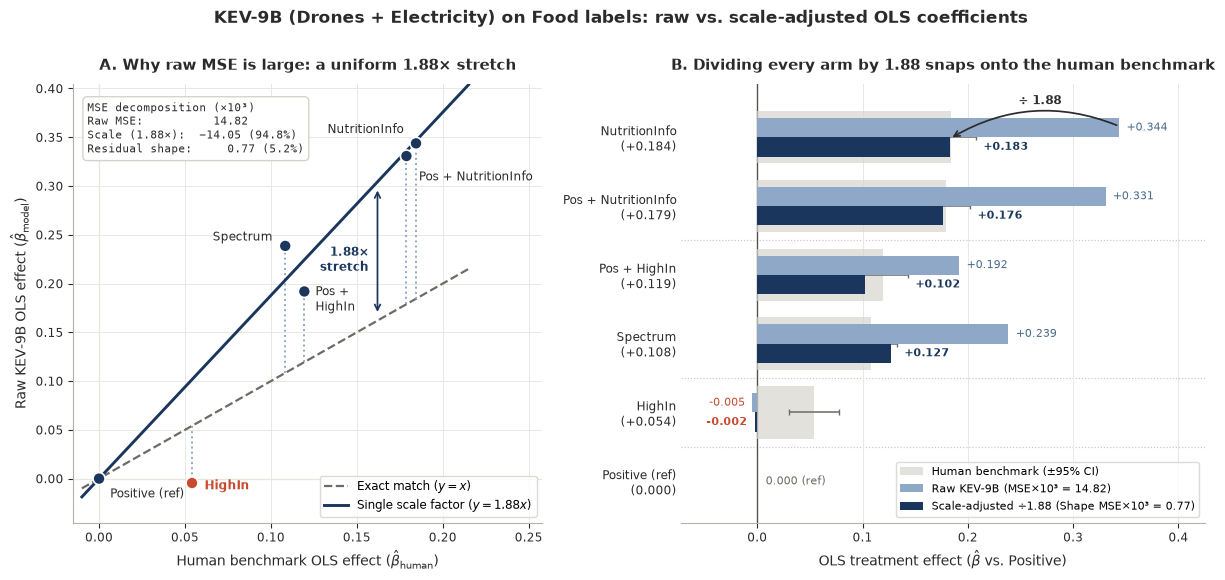

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_kev9b_raw_vs_scaled.png


In [4]:
target_model = "kev-9b"
target_slug = "row5_full_berke_wu_ce_oracle"
rec = row_lookup[(target_model, target_slug)]

raw_9b = kev_vals_desc[(target_model, target_slug)]
a_star = rec["_a_star"]
scale = rec["Scale"]               # 1 / a_star ≈ 1.88x
scaled_9b = a_star * raw_9b

# Compact arm-by-arm comparison table
comp_rows = []
for i, arm in enumerate(arm_order_desc):
    h_val = float(human_vals_desc[i])
    r_val = float(raw_9b[i])
    s_val = float(scaled_9b[i])
    comp_rows.append(
        {
            "Arm (Human order)": ARM_DISPLAY[arm],
            "Human beta": h_val,
            "Raw KEV-9B": r_val,
            "Raw / Human": (r_val / h_val) if h_val != 0.0 else np.nan,
            f"Scale-adjusted (÷{scale:.2f})": s_val,
            "Raw diff": r_val - h_val,
            "Scaled diff": s_val - h_val,
        }
    )
comp_df = pd.DataFrame(comp_rows)
display(
    comp_df.style.format(
        {
            "Human beta": "{:+.3f}",
            "Raw KEV-9B": "{:+.3f}",
            "Raw / Human": "{:.2f}x",
            f"Scale-adjusted (÷{scale:.2f})": "{:+.3f}",
            "Raw diff": "{:+.3f}",
            "Scaled diff": "{:+.3f}",
        },
        na_rep="—",
    ).hide(axis="index")
)

raw_mse = rec["Raw MSE (x1e3)"]
shape_mse = rec["Shape MSE (x1e3)"]
scale_share_pct = 100.0 * (raw_mse - shape_mse) / raw_mse

# Two-panel intuitive visual: (A) scatter geometry vs y=x and best-fit ray; (B) arm-by-arm contraction
RAW_COLOR = "#8FA8C8"
SCALED_COLOR = "#1B365D"

fig, (ax_sc, ax_bar) = plt.subplots(
    1,
    2,
    figsize=(14.6, 5.7),
    gridspec_kw={"width_ratios": [1.04, 1.16], "wspace": 0.28},
)

# --- Panel A: Scatter of Raw KEV-9B vs Human benchmark ---
x_grid = np.linspace(-0.01, 0.215, 100)
ax_sc.axhline(0.0, color="#CBC7BE", lw=0.8, zorder=1)
ax_sc.axvline(0.0, color="#CBC7BE", lw=0.8, zorder=1)
ax_sc.grid(color=GRID_COLOR, lw=0.7, zorder=0)

# 45-degree exact-match line (y = x) and best-fit proportionality ray (y = scale * x)
ax_sc.plot(x_grid, x_grid, color="#6E6A64", ls="--", lw=1.6, label="Exact match ($y = x$)", zorder=2)
ax_sc.plot(
    x_grid,
    scale * x_grid,
    color=SCALED_COLOR,
    ls="-",
    lw=2.1,
    label=f"Single scale factor ($y = {scale:.2f}x$)",
    zorder=3,
)

# Vertical dotted segments illustrating raw distance from y = x
for i in range(5):
    hx = float(human_vals_desc[i])
    ry = float(raw_9b[i])
    ax_sc.plot([hx, hx], [hx, ry], color=RAW_COLOR, lw=1.4, ls=":", zorder=2)

# Plot all 6 arms (highlight HighIn in coral since it sits slightly below 0)
pt_colors = [ERR_COLOR if (arm != "Positive" and raw_9b[i] < 0.0) else SCALED_COLOR for i, arm in enumerate(arm_order_desc)]
ax_sc.scatter(human_vals_desc, raw_9b, s=75, c=pt_colors, edgecolor="white", linewidth=1.2, zorder=5)

# Non-overlapping point labels
label_offsets = {
    "NutritionInfo vs Positive": (-9, 10, "right"),
    "Positive+NutritionInfo vs Positive": (9, -15, "left"),
    "Positive+HighIn vs Positive": (8, -6, "left"),
    "Spectrum vs Positive": (-9, 6, "right"),
    "HighIn vs Positive": (9, -2, "left"),
    "Positive": (8, -11, "left"),
}
scatter_labels = {**ARM_DISPLAY, "Positive+HighIn vs Positive": "Pos +\nHighIn"}
for i, arm in enumerate(arm_order_desc):
    dx, dy, ha = label_offsets[arm]
    ax_sc.annotate(
        scatter_labels[arm],
        xy=(human_vals_desc[i], raw_9b[i]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha=ha,
        va="center",
        fontsize=8.6,
        color=ERR_COLOR if pt_colors[i] == ERR_COLOR else TEXT_COLOR,
        fontweight="bold" if pt_colors[i] == ERR_COLOR else "normal",
    )

# MSE decomposition box in wide-open upper-left of Panel A
mse_box = (
    f"MSE decomposition (×10³)\n"
    f"Raw MSE:          {raw_mse:>5.2f}\n"
    f"Scale ({scale:.2f}×):  −{raw_mse - shape_mse:>5.2f} ({scale_share_pct:.1f}%)\n"
    f"Residual shape:    {shape_mse:>5.2f} ({100.0 - scale_share_pct:.1f}%)"
)
ax_sc.text(
    0.03,
    0.96,
    mse_box,
    transform=ax_sc.transAxes,
    ha="left",
    va="top",
    fontsize=8.0,
    family="DejaVu Sans Mono",
    color=TEXT_COLOR,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#D4D2CC", alpha=0.96),
    zorder=6,
)

# Double-headed vertical arrow in the open wedge at x=0.162 showing the 1.88x stretch
ax_sc.annotate(
    "",
    xy=(0.162, scale * 0.162 - 0.006),
    xytext=(0.162, 0.162 + 0.006),
    arrowprops=dict(arrowstyle="<->", color=SCALED_COLOR, lw=1.25),
    zorder=4,
)
ax_sc.text(
    0.157,
    0.224,
    f"{scale:.2f}×\nstretch",
    ha="right",
    va="center",
    fontsize=8.4,
    fontweight="bold",
    color=SCALED_COLOR,
)

ax_sc.set_xlim(-0.015, 0.258)
ax_sc.set_ylim(-0.045, 0.405)
ax_sc.set_xlabel("Human benchmark OLS effect ($\\hat{\\beta}_{\\mathrm{human}}$)", fontsize=9.8, color=TEXT_COLOR)
ax_sc.set_ylabel("Raw KEV-9B OLS effect ($\\hat{\\beta}_{\\mathrm{model}}$)", fontsize=9.8, color=TEXT_COLOR)
ax_sc.set_title(f"A. Why raw MSE is large: a uniform {scale:.2f}× stretch", fontsize=11.0, fontweight="bold", color=TEXT_COLOR, pad=10)
ax_sc.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#D4D2CC", fontsize=8.4)
ax_sc.spines["top"].set_visible(False)
ax_sc.spines["right"].set_visible(False)
ax_sc.spines["left"].set_color("#B5B2AA")
ax_sc.spines["bottom"].set_color("#B5B2AA")
ax_sc.tick_params(colors=TEXT_COLOR, labelsize=8.8)

# --- Panel B: Arm-by-arm comparison of Raw vs Scale-adjusted vs Human ---
y_pos = np.arange(len(arm_order_desc))
ax_bar.axvline(0.0, color="#55524D", lw=1.0, zorder=2)
ax_bar.grid(axis="x", color=GRID_COLOR, lw=0.7, zorder=0)
for dy in (1.5, 3.5, 4.5):
    ax_bar.axhline(dy, color="#CBC7BE", lw=0.85, ls=":", zorder=1)

# Human benchmark background bar + 95% CI
ax_bar.barh(
    y_pos,
    human_vals_desc,
    height=0.76,
    color=HUMAN_GHOST,
    alpha=0.70,
    label="Human benchmark (±95% CI)",
    zorder=2,
)
ax_bar.errorbar(
    human_vals_desc[:5],
    y_pos[:5],
    xerr=1.96 * human_se_desc[:5],
    fmt="none",
    ecolor="#6E6A64",
    elinewidth=1.1,
    capsize=2.5,
    zorder=3,
)

# Raw KEV-9B (top half of bar slot) vs Scale-adjusted KEV-9B (bottom half of bar slot)
bar_h = 0.28
ax_bar.barh(
    y_pos - bar_h / 2,
    raw_9b,
    height=bar_h,
    color=RAW_COLOR,
    label=f"Raw KEV-9B (MSE×10³ = {raw_mse:.2f})",
    zorder=4,
)
ax_bar.barh(
    y_pos + bar_h / 2,
    scaled_9b,
    height=bar_h,
    color=SCALED_COLOR,
    label=f"Scale-adjusted ÷{scale:.2f} (Shape MSE×10³ = {shape_mse:.2f})",
    zorder=5,
)

# Direct numeric labels for raw and scaled bars
for i, arm in enumerate(arm_order_desc):
    if arm == "Positive":
        ax_bar.text(0.008, y_pos[i], "0.000 (ref)", va="center", ha="left", fontsize=8.2, color=MUTED_COLOR)
        continue
    r_val = float(raw_9b[i])
    s_val = float(scaled_9b[i])
    h_hi = float(human_vals_desc[i] + 1.96 * human_se_desc[i])
    if r_val >= 0.0:
        ax_bar.text(r_val + 0.007, y_pos[i] - bar_h / 2, f"{r_val:+.3f}", va="center", ha="left", fontsize=8.0, color="#4A6B8A")
        ax_bar.text(max(s_val, h_hi) + 0.007, y_pos[i] + bar_h / 2, f"{s_val:+.3f}", va="center", ha="left", fontsize=8.2, color=SCALED_COLOR, fontweight="bold")
    else:
        ax_bar.text(r_val - 0.007, y_pos[i] - bar_h / 2, f"{r_val:+.3f}", va="center", ha="right", fontsize=8.0, color=ERR_COLOR)
        ax_bar.text(s_val - 0.007, y_pos[i] + bar_h / 2, f"{s_val:+.3f}", va="center", ha="right", fontsize=8.2, color=ERR_COLOR, fontweight="bold")

# Curved arrow above the top bar illustrating the uniform ÷1.88 contraction
ax_bar.annotate(
    "",
    xy=(scaled_9b[0], y_pos[0] + 0.02),
    xytext=(raw_9b[0], y_pos[0] - 0.16),
    arrowprops=dict(arrowstyle="->", color=TEXT_COLOR, lw=1.25, connectionstyle="arc3,rad=0.25"),
    zorder=6,
)
ax_bar.text(
    0.5 * (scaled_9b[0] + raw_9b[0]) + 0.005,
    y_pos[0] - 0.44,
    f"÷ {scale:.2f}",
    ha="center",
    va="bottom",
    fontsize=8.6,
    fontweight="bold",
    color=TEXT_COLOR,
)

ax_bar.set_yticks(y_pos)
ax_bar.set_yticklabels(
    [f"{ARM_DISPLAY[a]}\n({human_vals_desc[i]:+.3f})" if a != "Positive" else "Positive (ref)\n(0.000)" for i, a in enumerate(arm_order_desc)],
    fontsize=8.5,
    color=TEXT_COLOR,
)
ax_bar.set_xlim(-0.072, 0.425)
ax_bar.set_ylim(5.6, -0.78)
ax_bar.set_xlabel("OLS treatment effect ($\\hat{\\beta}$ vs. Positive)", fontsize=9.8, color=TEXT_COLOR)
ax_bar.set_title(f"B. Dividing every arm by {scale:.2f} snaps onto the human benchmark", fontsize=11.0, fontweight="bold", color=TEXT_COLOR, pad=10)
ax_bar.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#D4D2CC", fontsize=8.1)
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.spines["left"].set_visible(False)
ax_bar.spines["bottom"].set_color("#B5B2AA")
ax_bar.tick_params(axis="y", length=0)
ax_bar.tick_params(axis="x", colors=TEXT_COLOR, labelsize=8.8)

fig.suptitle(
    "KEV-9B (Drones + Electricity) on Food labels: raw vs. scale-adjusted OLS coefficients",
    y=1.01,
    fontsize=12.6,
    fontweight="bold",
    color=TEXT_COLOR,
)

out_png = Path("fig_kev9b_raw_vs_scaled.png")
fig.savefig(out_png, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out_png.resolve()}")

## Apparent raw-MSE contradiction: Off-the-shelf `KEV-0.8B` vs. choice-trained `KEV-9B` (`Drones + Electricity`)

On raw $\mathrm{MSE}_\beta$, off-the-shelf `KEV-0.8B` (`5.46`) looks **$2.7\times$ better** than choice-trained `KEV-9B` (`14.82`). Plotting both models side by side resolves the paradox: `KEV-0.8B` sits near $y = x$ only because its overall scale is muted (`0.94×`) while scattering wildly off any line ($99\%$ shape error), whereas `KEV-9B` hugs a straight $1.88\times$ ray ($94.8\%$ uniform scale) and achieves **$7.0\times$ lower shape MSE** (`0.77` vs. `5.41`).

Model,Raw MSE (x1e3),Scale share (%),Shape MSE (x1e3),Scale,Cosine,Sig. pairs
KEV-0.8B (Off-the-shelf),5.46,1.0%,5.41,0.94x,0.846,10/13
KEV-9B (Drones + Electricity),14.82,94.8%,0.77,1.88x,0.980,12/13


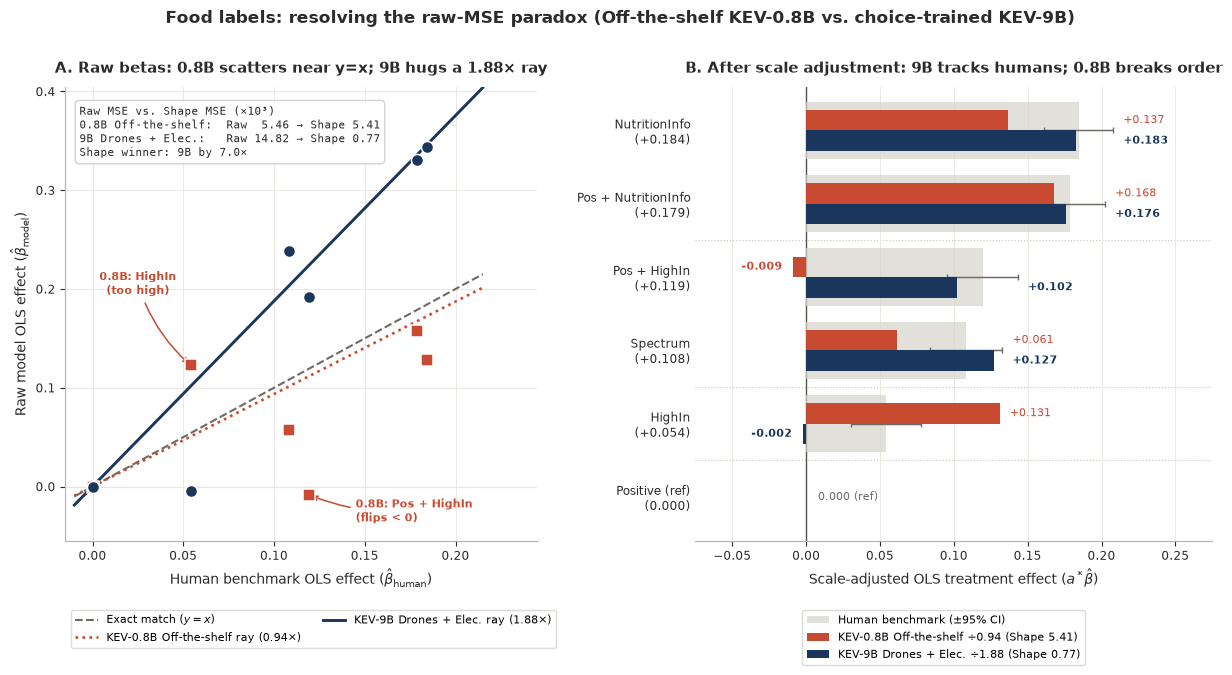

Saved /home/dw/github/decision-models-finetuning/code/papers/sim-respondents/analysis/post-hoc/fig_food_labels_contradiction_08b_vs_9b.png


In [5]:
small_key = ("kev-0.8b", BASE_SLUG)
large_key = ("kev-9b", "row5_full_berke_wu_ce_oracle")

rec_s = row_lookup[small_key]
rec_l = row_lookup[large_key]

raw_s = kev_vals_desc[small_key]
raw_l = kev_vals_desc[large_key]
scaled_s = rec_s["_a_star"] * raw_s
scaled_l = rec_l["_a_star"] * raw_l

SMALL_COLOR = "#C84B31"   # coral/terracotta for off-the-shelf KEV-0.8B
LARGE_COLOR = "#1B365D"   # deep navy for choice-trained KEV-9B

# Compact side-by-side decomposition table
decomp_df = pd.DataFrame(
    [
        {
            "Model": "KEV-0.8B (Off-the-shelf)",
            "Raw MSE (x1e3)": rec_s["Raw MSE (x1e3)"],
            "Scale share (%)": 100.0 * (rec_s["Raw MSE (x1e3)"] - rec_s["Shape MSE (x1e3)"]) / rec_s["Raw MSE (x1e3)"],
            "Shape MSE (x1e3)": rec_s["Shape MSE (x1e3)"],
            "Scale": rec_s["Scale"],
            "Cosine": rec_s["Cosine"],
            "Sig. pairs": rec_s["Sig. pairs"],
        },
        {
            "Model": "KEV-9B (Drones + Electricity)",
            "Raw MSE (x1e3)": rec_l["Raw MSE (x1e3)"],
            "Scale share (%)": 100.0 * (rec_l["Raw MSE (x1e3)"] - rec_l["Shape MSE (x1e3)"]) / rec_l["Raw MSE (x1e3)"],
            "Shape MSE (x1e3)": rec_l["Shape MSE (x1e3)"],
            "Scale": rec_l["Scale"],
            "Cosine": rec_l["Cosine"],
            "Sig. pairs": rec_l["Sig. pairs"],
        },
    ]
)
display(
    decomp_df.style.format(
        {
            "Raw MSE (x1e3)": "{:.2f}",
            "Scale share (%)": "{:.1f}%",
            "Shape MSE (x1e3)": "{:.2f}",
            "Scale": "{:.2f}x",
            "Cosine": "{:.3f}",
        }
    ).hide(axis="index")
)

fig, (ax_sc, ax_bar) = plt.subplots(
    1,
    2,
    figsize=(14.8, 5.9),
    gridspec_kw={"width_ratios": [1.05, 1.15], "wspace": 0.32},
)

# --- Panel A: Scatter of RAW betas for both models against Human benchmark ---
x_grid = np.linspace(-0.01, 0.215, 100)
ax_sc.axhline(0.0, color="#CBC7BE", lw=0.8, zorder=1)
ax_sc.axvline(0.0, color="#CBC7BE", lw=0.8, zorder=1)
ax_sc.grid(color=GRID_COLOR, lw=0.7, zorder=0)

ax_sc.plot(x_grid, x_grid, color="#6E6A64", ls="--", lw=1.5, label="Exact match ($y = x$)", zorder=2)
ax_sc.plot(
    x_grid,
    rec_s["Scale"] * x_grid,
    color=SMALL_COLOR,
    ls=":",
    lw=1.9,
    label=f"KEV-0.8B Off-the-shelf ray ({rec_s['Scale']:.2f}×)",
    zorder=3,
)
ax_sc.plot(
    x_grid,
    rec_l["Scale"] * x_grid,
    color=LARGE_COLOR,
    ls="-",
    lw=2.1,
    label=f"KEV-9B Drones + Elec. ray ({rec_l['Scale']:.2f}×)",
    zorder=3,
)

# Scatter points (6 arms each)
ax_sc.scatter(
    human_vals_desc,
    raw_s,
    s=68,
    marker="s",
    color=SMALL_COLOR,
    edgecolor="white",
    linewidth=1.1,
    zorder=5,
)
ax_sc.scatter(
    human_vals_desc,
    raw_l,
    s=76,
    marker="o",
    color=LARGE_COLOR,
    edgecolor="white",
    linewidth=1.1,
    zorder=6,
)

# Highlight the two biggest structural errors of KEV-0.8B Off-the-shelf directly on the scatter
ax_sc.annotate(
    "0.8B: HighIn\n(too high)",
    xy=(human_vals_desc[4], raw_s[4]),
    xytext=(0.025, 0.195),
    ha="center",
    fontsize=8.0,
    fontweight="bold",
    color=SMALL_COLOR,
    arrowprops=dict(arrowstyle="->", color=SMALL_COLOR, lw=1.1, connectionstyle="arc3,rad=0.14"),
)
ax_sc.annotate(
    "0.8B: Pos + HighIn\n(flips < 0)",
    xy=(human_vals_desc[2], raw_s[2]),
    xytext=(0.145, -0.025),
    ha="left",
    va="center",
    fontsize=8.0,
    fontweight="bold",
    color=SMALL_COLOR,
    arrowprops=dict(arrowstyle="->", color=SMALL_COLOR, lw=1.1, connectionstyle="arc3,rad=-0.12"),
)

# Callout box showing the ranking reversal between Raw MSE and Shape MSE
box_txt = (
    "Raw MSE vs. Shape MSE (×10³)\n"
    f"0.8B Off-the-shelf:  Raw {rec_s['Raw MSE (x1e3)']:>5.2f} → Shape {rec_s['Shape MSE (x1e3)']:>4.2f}\n"
    f"9B Drones + Elec.:   Raw {rec_l['Raw MSE (x1e3)']:>5.2f} → Shape {rec_l['Shape MSE (x1e3)']:>4.2f}\n"
    f"Shape winner: 9B by {rec_s['Shape MSE (x1e3)'] / rec_l['Shape MSE (x1e3)']:.1f}×"
)
ax_sc.text(
    0.03,
    0.96,
    box_txt,
    transform=ax_sc.transAxes,
    ha="left",
    va="top",
    fontsize=7.7,
    family="DejaVu Sans Mono",
    color=TEXT_COLOR,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#D4D2CC", alpha=0.96),
    zorder=7,
)

ax_sc.set_xlim(-0.015, 0.245)
ax_sc.set_ylim(-0.055, 0.405)
ax_sc.set_xlabel("Human benchmark OLS effect ($\\hat{\\beta}_{\\mathrm{human}}$)", fontsize=9.8, color=TEXT_COLOR)
ax_sc.set_ylabel("Raw model OLS effect ($\\hat{\\beta}_{\\mathrm{model}}$)", fontsize=9.8, color=TEXT_COLOR)
ax_sc.set_title("A. Raw betas: 0.8B scatters near y=x; 9B hugs a 1.88× ray", fontsize=10.6, fontweight="bold", color=TEXT_COLOR, pad=10)
ax_sc.legend(loc="upper left", bbox_to_anchor=(0.0, -0.14), ncol=2, frameon=True, facecolor="white", edgecolor="#D4D2CC", fontsize=8.0)
ax_sc.spines["top"].set_visible(False)
ax_sc.spines["right"].set_visible(False)
ax_sc.spines["left"].set_color("#B5B2AA")
ax_sc.spines["bottom"].set_color("#B5B2AA")
ax_sc.tick_params(colors=TEXT_COLOR, labelsize=8.8)

# --- Panel B: Scale-adjusted arm-by-arm bars for both models vs Human benchmark ---
y_pos = np.arange(len(arm_order_desc))
ax_bar.axvline(0.0, color="#55524D", lw=1.0, zorder=2)
ax_bar.grid(axis="x", color=GRID_COLOR, lw=0.7, zorder=0)
for dy in (1.5, 3.5, 4.5):
    ax_bar.axhline(dy, color="#CBC7BE", lw=0.85, ls=":", zorder=1)

ax_bar.barh(y_pos, human_vals_desc, height=0.78, color=HUMAN_GHOST, alpha=0.72, label="Human benchmark (±95% CI)", zorder=2)
ax_bar.errorbar(
    human_vals_desc[:5],
    y_pos[:5],
    xerr=1.96 * human_se_desc[:5],
    fmt="none",
    ecolor="#6E6A64",
    elinewidth=1.05,
    capsize=2.4,
    zorder=3,
)

bar_h = 0.28
ax_bar.barh(
    y_pos - bar_h / 2,
    scaled_s,
    height=bar_h,
    color=SMALL_COLOR,
    label=f"KEV-0.8B Off-the-shelf ÷{rec_s['Scale']:.2f} (Shape {rec_s['Shape MSE (x1e3)']:.2f})",
    zorder=4,
)
ax_bar.barh(
    y_pos + bar_h / 2,
    scaled_l,
    height=bar_h,
    color=LARGE_COLOR,
    label=f"KEV-9B Drones + Elec. ÷{rec_l['Scale']:.2f} (Shape {rec_l['Shape MSE (x1e3)']:.2f})",
    zorder=5,
)

for i, arm in enumerate(arm_order_desc):
    if arm == "Positive":
        ax_bar.text(0.008, y_pos[i], "0.000 (ref)", va="center", ha="left", fontsize=8.0, color=MUTED_COLOR)
        continue
    vs = float(scaled_s[i])
    vl = float(scaled_l[i])
    h_hi = float(human_vals_desc[i] + 1.96 * human_se_desc[i])
    if vs >= 0.0:
        ax_bar.text(max(vs, h_hi) + 0.007, y_pos[i] - bar_h / 2, f"{vs:+.3f}", va="center", ha="left", fontsize=7.9, color=SMALL_COLOR)
    else:
        ax_bar.text(vs - 0.007, y_pos[i] - bar_h / 2, f"{vs:+.3f}", va="center", ha="right", fontsize=7.9, color=SMALL_COLOR, fontweight="bold")
    if vl >= 0.0:
        ax_bar.text(max(vl, h_hi) + 0.007, y_pos[i] + bar_h / 2, f"{vl:+.3f}", va="center", ha="left", fontsize=8.0, color=LARGE_COLOR, fontweight="bold")
    else:
        ax_bar.text(vl - 0.007, y_pos[i] + bar_h / 2, f"{vl:+.3f}", va="center", ha="right", fontsize=8.0, color=LARGE_COLOR, fontweight="bold")

ax_bar.set_yticks(y_pos)
ax_bar.set_yticklabels(
    [f"{ARM_DISPLAY[a]}\n({human_vals_desc[i]:+.3f})" if a != "Positive" else "Positive (ref)\n(0.000)" for i, a in enumerate(arm_order_desc)],
    fontsize=8.3,
    color=TEXT_COLOR,
)
ax_bar.set_xlim(-0.075, 0.275)
ax_bar.set_ylim(5.6, -0.6)
ax_bar.set_xlabel("Scale-adjusted OLS treatment effect ($a^*\\hat{\\beta}$)", fontsize=9.8, color=TEXT_COLOR)
ax_bar.set_title("B. After scale adjustment: 9B tracks humans; 0.8B breaks order", fontsize=10.6, fontweight="bold", color=TEXT_COLOR, pad=10)
ax_bar.legend(loc="upper center", bbox_to_anchor=(0.48, -0.14), ncol=1, frameon=True, facecolor="white", edgecolor="#D4D2CC", fontsize=8.0)
ax_bar.spines["top"].set_visible(False)
ax_bar.spines["right"].set_visible(False)
ax_bar.spines["left"].set_visible(False)
ax_bar.spines["bottom"].set_color("#B5B2AA")
ax_bar.tick_params(axis="y", length=0)
ax_bar.tick_params(axis="x", colors=TEXT_COLOR, labelsize=8.8)

fig.suptitle(
    "Food labels: resolving the raw-MSE paradox (Off-the-shelf KEV-0.8B vs. choice-trained KEV-9B)",
    y=1.01,
    fontsize=12.4,
    fontweight="bold",
    color=TEXT_COLOR,
)

out_contra1 = Path("fig_food_labels_contradiction_08b_vs_9b.png")
fig.savefig(out_contra1, dpi=220, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved {out_contra1.resolve()}")